In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "4" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch04_elf_loader_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 4.5 ローダを改良する (`osbook_day04d`) — ELF形式とセグメント配置

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/4/4.5_Loading_ELF_Segments_Properly.ipynb)

本節では、第3章（3.3節・`day03a`）から利用してきたブートローダ（`MikanLoaderPkg/Main.c`）のカーネル読み込み処理を抜本的に改良し、**ELF64（*Executable and Linkable Format*）仕様に厳密に準拠したセグメント配置ローダ** を構築します。

---

### 🎯 本節の学習目標 (Learning Objectives)

1. **従来のベタコピー方式が抱えていた3大破綻要因の理解**:
   - なぜ `0x100000` へのファイル丸ごと直読み込み（ベタコピー）がこれまで動作していたのか？
   - ELFヘッダ混入、`.bss`（未初期化大域変数）の未確保・ゴミ露出、メモリ破壊のメカニズム。
2. **ELF-64 仕様とヘッダ構造の完全理解**:
   - `Elf64_Ehdr`（64バイトELFヘッダ）のマジックナンバー、アーキテクチャ判定、プログラムヘッダテーブル参照。
   - `Elf64_Phdr`（56バイトプログラムヘッダ）のセグメント種別（`PT_LOAD` 等）、ファイルオフセット、仮想アドレス、ファイルサイズとメモリサイズ。
3. **セグメント配置と `.bss` ゼロクリアの数理導出**:
   - `p_filesz`（ファイル内実データ長）と `p_memsz`（メモリ上専有領域長）の差分数理：$\text{BSS\_Size} = p\_\text{memsz} - p\_\text{filesz}$。
   - C/C++規格における「未初期化大域変数はゼロ初期化される」保証をOSカーネルが果たすための `SetMem`（`memset 0`）。
4. **二段階ロード（Two-Stage Loading）アーキテクチャの実装**:
   - 一時バッファ確保（`AllocatePool`） $\to$ 配置アドレス範囲走査（`CalcLoadAddressRange`） $\to$ ページ計算と本番RAM確保（`AllocatePages`） $\to$ セグメント複写 & ゼロ埋め（`CopyLoadSegments`） $\to$ 一時バッファ解放（`FreePool`）。
5. **エントリポイントアドレスの導出とカーネル起動**:
   - メモリ先頭（`kernel_first_addr + 24`）からエントリポイント `KernelMain` を正しく特定してジャンプするシーケンスの検証。


## 1. 従来の「ベタコピー」方式が抱える3大破綻要因

第3章（3.3節・`day03a`）から第4章4.4節（`day04c`）まで、ブートローダ `Main.c` は以下のようにカーネルファイルを読み込んでいました：

```c
// 従来の危険なベタコピー方式 (day03a 〜 day04c)
EFI_PHYSICAL_ADDRESS kernel_base_addr = 0x100000;
status = gBS->AllocatePages(
    AllocateAddress, EfiLoaderData,
    (kernel_file_size + 0xfff) / 0x1000, &kernel_base_addr);

status = kernel_file->Read(kernel_file, &kernel_file_size, (VOID*)kernel_base_addr);
UINT64 entry_addr = *(UINT64*)(kernel_base_addr + 24);
```

一見するとシンプルで美しく見えますが、この実装は **OSカーネルが大規模化・本格化するにつれて確実に致命的クラッシュを引き起こす爆弾** を抱えていました。

```
【従来の単純ベタ読み込み (Naive Direct File Copy)】
File (kernel.elf):  [ Elf64_Ehdr (64B) | Elf64_Phdr (112B) | .text (Code) | .rodata | .data ]
                            ↓↓↓ そのまま丸ごと 0x100000 にコピー ↓↓↓
RAM (0x100000):     [ Elf64_Ehdr (64B) | Elf64_Phdr (112B) | .text (Code) | .rodata | .data ]
                     ↑
                 0x100000 は本来コード (.text) が置かれるべき場所なのに、
                 無関係な ELF ヘッダデータがメモリを占有してしまう！
                 さらに .bss (未初期化変数) 領域はファイルに無いため確保すらされない！
```

### ❌ 破綻要因 1: ELFヘッダ混入と仮想アドレスの不整合
ELFファイル先頭には、OSカーネル実行時には不要な **メタ情報（`Elf64_Ehdr` 64バイト、プログラムヘッダ配列）** が記録されています。
リンカ（`ld.lld`）は、コードセグメント（`.text`）やデータセグメント（`.data`）を特定の仮想アドレス（例: `0x100000` や `0x101000`）に配置することを想定してリンクしています。
ファイル全体を先頭からベタ書きしてしまうと、各セクションのメモリ配置アドレスがヘッダのサイズ分だけズレるか、あるいはリンカがヘッダを含めてアライメント調整した特殊なバイナリでしか動かなくなります。

### ❌ 破綻要因 2: `.bss` 領域の未確保と未初期化（ゴミデータの露出）
C/C++ プログラムにおいて、初期値を持たない大域変数（例: `static uint8_t g_buffer[1024 * 1024];`）やゼロ初期化された変数は、実行ファイルのサイズを節約するために ELF ファイル内には実データとして記録されず、**`.bss`（*Block Started by Symbol*）セクション** としてヘッダ情報にサイズのみが記録されます。
- ファイル上のサイズ: $p\_\text{filesz} = 0$
- メモリ上の所要量: $p\_\text{memsz} = 1048576$ (1MiB)

従来の方式では `kernel_file_size`（ファイルサイズ）分しかメモリを確保せず、ファイルの内容しか書き込みません。そのため：
1. **メモリ確保不足**: `.bss` のサイズがメモリ確保量に加算されないため、後続の未確保メモリ領域へ不正アクセス（バッファオーバーフロー）が発生します。
2. **ゼロ初期化漏れ**: C/C++ 言語仕様では「大域変数・静的変数はゼロ初期化される」ことが保証されていますが、ベタ読みでは物理RAMに残存する前時代のゴミデータ（`0xFF` やランダム値）がそのまま残り、未定義動作やカーネルパニックを引き起こします。

### ❌ 破綻要因 3: マルチセグメントとページアライメント境界の不一致
ELFファイル内ではファイルサイズを小さくするためセグメント間が詰めて配置されることがありますが、CPUのMMU（*Memory Management Unit*）は **4KiB（`0x1000`）ページ境界** でしかアクセス保護属性（Read/Write/Execute）を適用できません。
ファイル上のオフセットとメモリ上のページ境界を適切に切り離して配置する正規ローダが不可欠です。


## 2. ELF-64 (*Executable and Linkable Format*) の基本構造

UNIX / Linux / MikanOS で標準採用されている実行可能バイナリ形式 **ELF-64** は、2つのヘッダ構造体によって制御されます。

### ① `Elf64_Ehdr` (64バイト: ELF全体ヘッダ)
バイナリの先頭（オフセット 0）に必ず配置され、CPUアーキテクチャやプログラムヘッダテーブルの配置場所を示します。

| オフセット | サイズ | フィールド名 | 型 | 役割・MikanOSでの期待値 |
|:---:|:---:|---|---|---|
| `0x00` | 16B | `e_ident[16]` | `unsigned char` | マジックナンバー `\x7fELF`、64-bit(`2`)、Little-endian(`1`)、System V ABI(`0`) |
| `0x10` | 2B | `e_type` | `Elf64_Half` | オブジェクト種別 (`ET_EXEC = 2`: 実行可能ファイル, `ET_DYN = 3`: 共有オブジェクト) |
| `0x12` | 2B | `e_machine` | `Elf64_Half` | ターゲットCPU (`EM_X86_64 = 62 = 0x3E`: AMD x86-64) |
| `0x14` | 4B | `e_version` | `Elf64_Word` | ELF仕様バージョン (`EV_CURRENT = 1`) |
| `0x18` | 8B | `e_entry` | `Elf64_Addr` | **カーネル実行開始アドレス (エントリポイント: `KernelMain`)** |
| `0x20` | 8B | `e_phoff` | `Elf64_Off` | **プログラムヘッダテーブルのファイル内開始オフセット** |
| `0x28` | 8B | `e_shoff` | `Elf64_Off` | セクションヘッダテーブルのファイル内開始オフセット |
| `0x30` | 4B | `e_flags` | `Elf64_Word` | プロセッサ固有フラグ (`0`) |
| `0x34` | 2B | `e_ehsize` | `Elf64_Half` | ELFヘッダ自体のサイズ (`64` バイト) |
| `0x36` | 2B | `e_phentsize`| `Elf64_Half` | プログラムヘッダ1個のバイトサイズ (`56` バイト) |
| `0x38` | 2B | `e_phnum` | `Elf64_Half` | **プログラムヘッダの個数** |

> [!NOTE]
> **エントリポイントオフセット 24 の真相**:
> `offsetof(Elf64_Ehdr, e_entry) == 24` です。
> MikanOS で `*(UINT64*)(kernel_first_addr + 24)` と記述できるのは、LLD リンカが最初のセグメント（`0x100000`）の先頭に `Elf64_Ehdr` をそのまま配置しているため、メモリ先頭から 24 バイト目がそのまま `e_entry` になるからです！

---

### ② `Elf64_Phdr` (56バイト: プログラムヘッダ)
OSローダに対して、**「ファイルのどの部分を、メモリのどのアドレスへ、何バイト展開し、どう保護するか」** を指示する記述子です。

| オフセット | サイズ | フィールド名 | 型 | 役割・セグメント配置規則 |
|:---:|:---:|---|---|---|
| `0x00` | 4B | `p_type` | `Elf64_Word` | セグメント種別 (`PT_LOAD = 1`: メモリロード対象, `PT_DYNAMIC = 2`, etc.) |
| `0x04` | 4B | `p_flags` | `Elf64_Word` | アクセス権限ビット (`PF_X = 1`: 実行, `PF_W = 2`: 書込, `PF_R = 4`: 読出) |
| `0x08` | 8B | `p_offset` | `Elf64_Off` | **ファイル先頭からのオフセット (CopyMem のコピー元)** |
| `0x10` | 8B | `p_vaddr` | `Elf64_Addr` | **配置先仮想アドレス (CopyMem のコピー先)** |
| `0x18` | 8B | `p_paddr` | `Elf64_Addr` | 物理アドレス (通常は無視) |
| `0x20` | 8B | `p_filesz` | `Elf64_Xword`| **ファイル内に存在する実データ長 (CopyMem のバイト数)** |
| `0x28` | 8B | `p_memsz` | `Elf64_Xword`| **メモリ上で専有すべき総サイズ ($p\_\text{memsz} \ge p\_\text{filesz}$)** |
| `0x30` | 8B | `p_align` | `Elf64_Xword`| アライメント境界 (例: `0x1000` = 4096バイトページ境界) |


In [2]:
from common import (
    Elf64Ehdr,
    Elf64Phdr,
    ElfLoaderSimulator,
    PT_LOAD,
    PF_R,
    PF_W,
    PF_X,
)

# 1. 典型的な MikanOS カーネルの ELF ヘッダ構造を Python で再現
mock_segments = [
    {
        "type": PT_LOAD,
        "flags": PF_R | PF_X,
        "vaddr": 0x100000,
        "data": b"\x48\x31\xc0\xc3" + b"\x90" * 252,  # 256 bytes code (.text / .rodata)
        "memsz": 256,
        "align": 0x1000,
    },
    {
        "type": PT_LOAD,
        "flags": PF_R | PF_W,
        "vaddr": 0x101000,
        "data": b"\x55" * 128,  # 128 bytes initialized data (.data)
        "memsz": 512,          # 512 bytes total -> 384 bytes .bss!
        "align": 0x1000,
    },
]

mock_elf = ElfLoaderSimulator.build_mock_elf(entry=0x100000, segments=mock_segments)
ehdr, phdrs = ElfLoaderSimulator.parse_elf(mock_elf)

print(f"=== ELF-64 ヘッダ解析結果 ===")
print(f"マジックナンバー: {ehdr.e_ident[:4]} (有効: {ehdr.is_valid_magic})")
print(f"ビット幅: {'64-bit' if ehdr.is_64bit else '32-bit'}")
print(f"ターゲットCPU: {ehdr.e_machine} ({'x86-64' if ehdr.is_x86_64 else 'Other'})")
print(f"エントリポイント: 0x{ehdr.e_entry:06X}")
print(f"プログラムヘッダ数: {ehdr.e_phnum} 個 (オフセット: {ehdr.e_phoff}B, 各サイズ: {ehdr.e_phentsize}B)\n")

print(f"=== プログラムヘッダ (セグメント) 一覧 ===")
for i, ph in enumerate(phdrs):
    print(f"[{i}] Type: {'PT_LOAD' if ph.is_load else 'OTHER'}, Flags: {ph.flags_str}, "
          f"Offset: 0x{ph.p_offset:X}, VAddr: 0x{ph.p_vaddr:X}, "
          f"FileSz: {ph.p_filesz}B, MemSz: {ph.p_memsz}B, BSS: {ph.bss_size}B")


=== ELF-64 ヘッダ解析結果 ===
マジックナンバー: b'\x7fELF' (有効: True)
ビット幅: 64-bit
ターゲットCPU: 62 (x86-64)
エントリポイント: 0x100000
プログラムヘッダ数: 2 個 (オフセット: 64B, 各サイズ: 56B)

=== プログラムヘッダ (セグメント) 一覧 ===
[0] Type: PT_LOAD, Flags: R-X, Offset: 0xB0, VAddr: 0x100000, FileSz: 256B, MemSz: 256B, BSS: 0B
[1] Type: PT_LOAD, Flags: RW-, Offset: 0x1B0, VAddr: 0x101000, FileSz: 128B, MemSz: 512B, BSS: 384B


## 3. 改良型ローダの二段階アーキテクチャ (Two-Stage Loader)

MikanOS 公式タグ `osbook_day04d` において、ブートローダ `MikanLoaderPkg/Main.c` は以下の **5段階の堅牢なロードシーケンス** へ全面刷新されました。

```mermaid
sequenceDiagram
    autonumber
    participant BL as BootLoader (Main.c)
    participant FS as UEFI FileSystem
    participant BS as UEFI BootServices
    participant RAM as Physical Memory

    Note over BL,RAM: 【第1段階: 一時バッファへの全ファイル吸い出し】
    BL->>BS: AllocatePool(EfiLoaderData, FileSize, &kernel_buffer)
    BL->>FS: Read(kernel_file, FileSize, kernel_buffer)

    Note over BL,RAM: 【第2段階: 配置アドレス範囲の厳密計算】
    BL->>BL: CalcLoadAddressRange(ehdr, &first, &last)
    BL->>BL: num_pages = (last - first + 0xfff) / 0x1000

    Note over BL,RAM: 【第3段階: 本番メモリの過不足ないページ確保】
    BL->>BS: AllocatePages(AllocateAddress, EfiLoaderData, num_pages, &first)

    Note over BL,RAM: 【第4段階: PT_LOAD セグメント複写 & BSS ゼロクリア】
    BL->>RAM: CopyMem(p_vaddr, segm_in_file, p_filesz)
    BL->>RAM: SetMem(p_vaddr + p_filesz, p_memsz - p_filesz, 0)

    Note over BL,RAM: 【第5段階: 後始末とカーネルエントリポイント呼び出し】
    BL->>BS: FreePool(kernel_buffer)
    BL->>BS: ExitBootServices()
    BL->>RAM: Jump to entry_addr (KernelMain)
```

---

### `CalcLoadAddressRange` の数理とC実装

`MikanLoaderPkg/Main.c` に追加された範囲計算関数です：

```c
void CalcLoadAddressRange(Elf64_Ehdr* ehdr, UINT64* first, UINT64* last) {
  Elf64_Phdr* phdr = (Elf64_Phdr*)((UINT64)ehdr + ehdr->e_phoff);
  *first = MAX_UINT64;
  *last = 0;
  for (Elf64_Half i = 0; i < ehdr->e_phnum; ++i) {
    if (phdr[i].p_type != PT_LOAD) continue;
    *first = MIN(*first, phdr[i].p_vaddr);
    *last = MAX(*last, phdr[i].p_vaddr + phdr[i].p_memsz);
  }
}
```

- **アルゴリズム**: 全プログラムヘッダを走査し、`PT_LOAD` セグメントの中で最も小さい仮想アドレス $\min(p\_\text{vaddr})$ を `*first` に、最も大きい終端アドレス $\max(p\_\text{vaddr} + p\_\text{memsz})$ を `*last` に記録します。
- **所要ページ数計算**: 
  $$\text{num\_pages} = \left\lfloor \frac{\text{last} - \text{first} + \text{0xFFF}}{\text{0x1000}} \right\rfloor$$
  4KiB境界に切り上げることで、BSS領域を含めた全セグメント領域を完全にカバーする物理RAMページを `gBS->AllocatePages` で確保します。

---

### `CopyLoadSegments` と `.bss` ゼロクリアのC実装

```c
void CopyLoadSegments(Elf64_Ehdr* ehdr) {
  Elf64_Phdr* phdr = (Elf64_Phdr*)((UINT64)ehdr + ehdr->e_phoff);
  for (Elf64_Half i = 0; i < ehdr->e_phnum; ++i) {
    if (phdr[i].p_type != PT_LOAD) continue;

    UINT64 segm_in_file = (UINT64)ehdr + phdr[i].p_offset;
    CopyMem((VOID*)phdr[i].p_vaddr, (VOID*)segm_in_file, phdr[i].p_filesz);

    UINTN remain_bytes = phdr[i].p_memsz - phdr[i].p_filesz;
    SetMem((VOID*)(phdr[i].p_vaddr + phdr[i].p_filesz), remain_bytes, 0);
  }
}
```

- **`CopyMem`**: ファイル上の実データ $p\_\text{filesz}$ バイトを `p_vaddr` へ転送（機械語コードや初期化済み大域変数）。
- **`SetMem`**: $p\_\text{memsz} - p\_\text{filesz}$ バイトの差分領域を **厳密にゼロ埋め** します。これにより、C++の未初期化大域変数が仕様通り `0` で起動することが保証されます！


In [3]:
# Python による二段階ローダとメモリ展開シミュレーション
first_addr, last_addr = ElfLoaderSimulator.calc_load_address_range(ehdr, phdrs)
num_pages = ElfLoaderSimulator.calc_required_pages(first_addr, last_addr, 4096)
total_bytes = num_pages * 4096

print(f"=== アドレス範囲と必要ページ数の計算 ===")
print(f"ロード開始仮想アドレス (first): 0x{first_addr:06X}")
print(f"ロード終了仮想アドレス (last) : 0x{last_addr:06X}")
print(f"所要アドレススパン: {last_addr - first_addr} バイト")
print(f"必要 4KiB ページ数: {num_pages} ページ ({total_bytes} バイト確保)\n")

# 物理メモリを模したバイト配列 (初期状態は未初期化ゴミ 0xFF で汚染)
simulated_ram = bytearray(b"\xFF" * total_bytes)

# セグメント展開と BSS ゼロクリアを実行
res = ElfLoaderSimulator.copy_load_segments(ehdr, phdrs, mock_elf, simulated_ram, base_vaddr=first_addr)

print(f"=== セグメント配置完了レポート ===")
print(f"展開セグメント数: {res['loaded_count']}")
for seg in res["segments"]:
    print(f"セグメント [{seg['index']}]: VAddr 0x{seg['vaddr']:X}, FileSz {seg['filesz']}B, "
          f"MemSz {seg['memsz']}B (BSSゼロクリア: {seg['bss_size']}B)")

# BSS 領域が確実に 0x00 になっているかサンプリング検証
seg1_bss_offset = (0x101000 - 0x100000) + 128  # VAddr 0x101080
bss_samples = simulated_ram[seg1_bss_offset : seg1_bss_offset + 16]
print(f"\n.bss 領域サンプル値 (16バイト): {list(bss_samples)}")
assert all(b == 0 for b in bss_samples), "BSS must be strictly zero-filled!"
print("✅ .bss 領域のゼロクリアが完全に成功しています！")


=== アドレス範囲と必要ページ数の計算 ===
ロード開始仮想アドレス (first): 0x100000
ロード終了仮想アドレス (last) : 0x101200
所要アドレススパン: 4608 バイト
必要 4KiB ページ数: 2 ページ (8192 バイト確保)

=== セグメント配置完了レポート ===
展開セグメント数: 2
セグメント [0]: VAddr 0x100000, FileSz 256B, MemSz 256B (BSSゼロクリア: 0B)
セグメント [1]: VAddr 0x101000, FileSz 128B, MemSz 512B (BSSゼロクリア: 384B)

.bss 領域サンプル値 (16バイト): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
✅ .bss 領域のゼロクリアが完全に成功しています！


## 4. 高解像度アーキテクチャ図版の可視化

本節で導出した ELF-64 バイナリ構造、プログラムヘッダによるセグメント写像、および BSS ゼロクリアの物理メカニズムを高解像度図版（DPI 300）としてレンダリングします。

1. **図 4.9: ELF-64 ファイルバイナリ構造と仮想メモリ空間へのセグメント写像 (`fig4_09_elf_segment_structure.png`)**
   - オンディスクの ELF ファイル構造（`Elf64_Ehdr`, `Elf64_Phdr`, 各セグメント）と、RAM上の仮想アドレス空間への `CopyMem` 写像関係を図解。
2. **図 4.10: 2段階ローダ処理フローと .bss ゼロクリア詳細メカニズム (`fig4_10_pt_load_and_bss_clearing.png`)**
   - 従来のベタコピー方式が抱える3大欠陥と、改良型2段階ローダ（AllocatePool $\to$ CalcRange $\to$ AllocatePages $\to$ CopyLoad $\to$ FreePool）の処理フロー、および `p_filesz` と `p_memsz` の差分を `SetMem` でゼロ埋めするメモリ配置。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:17452: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:17575: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


生成された図版を表示します:


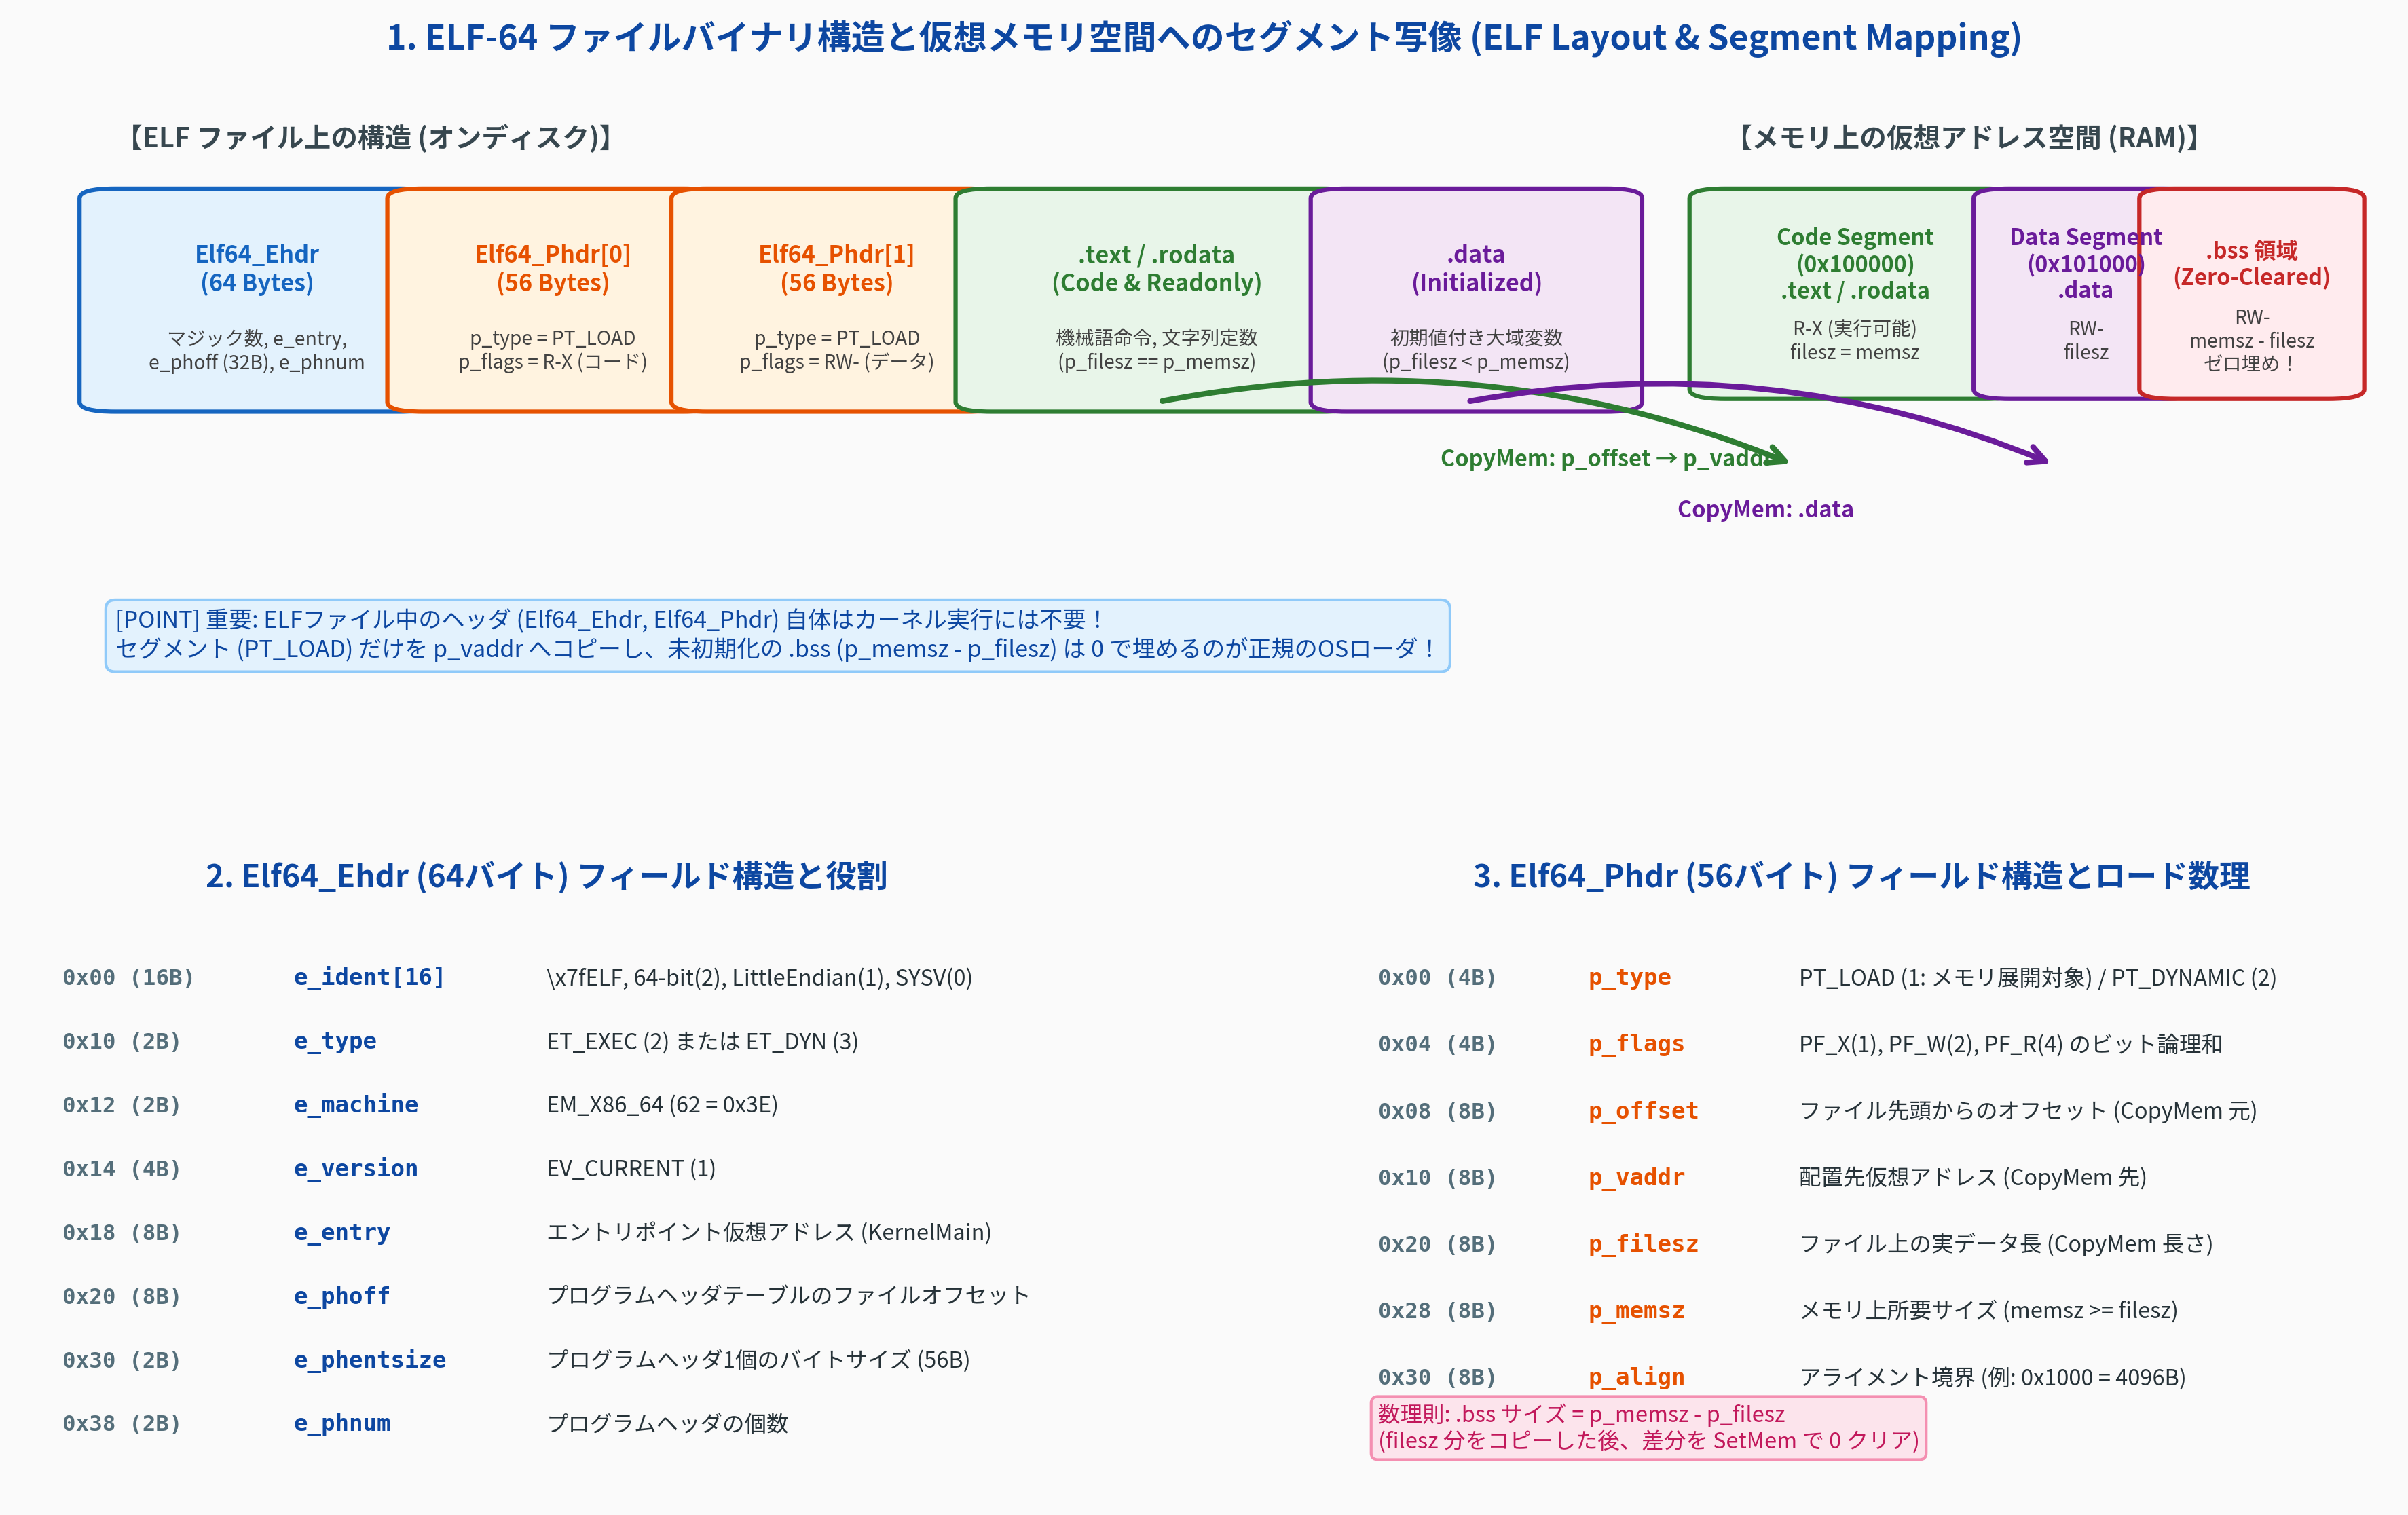

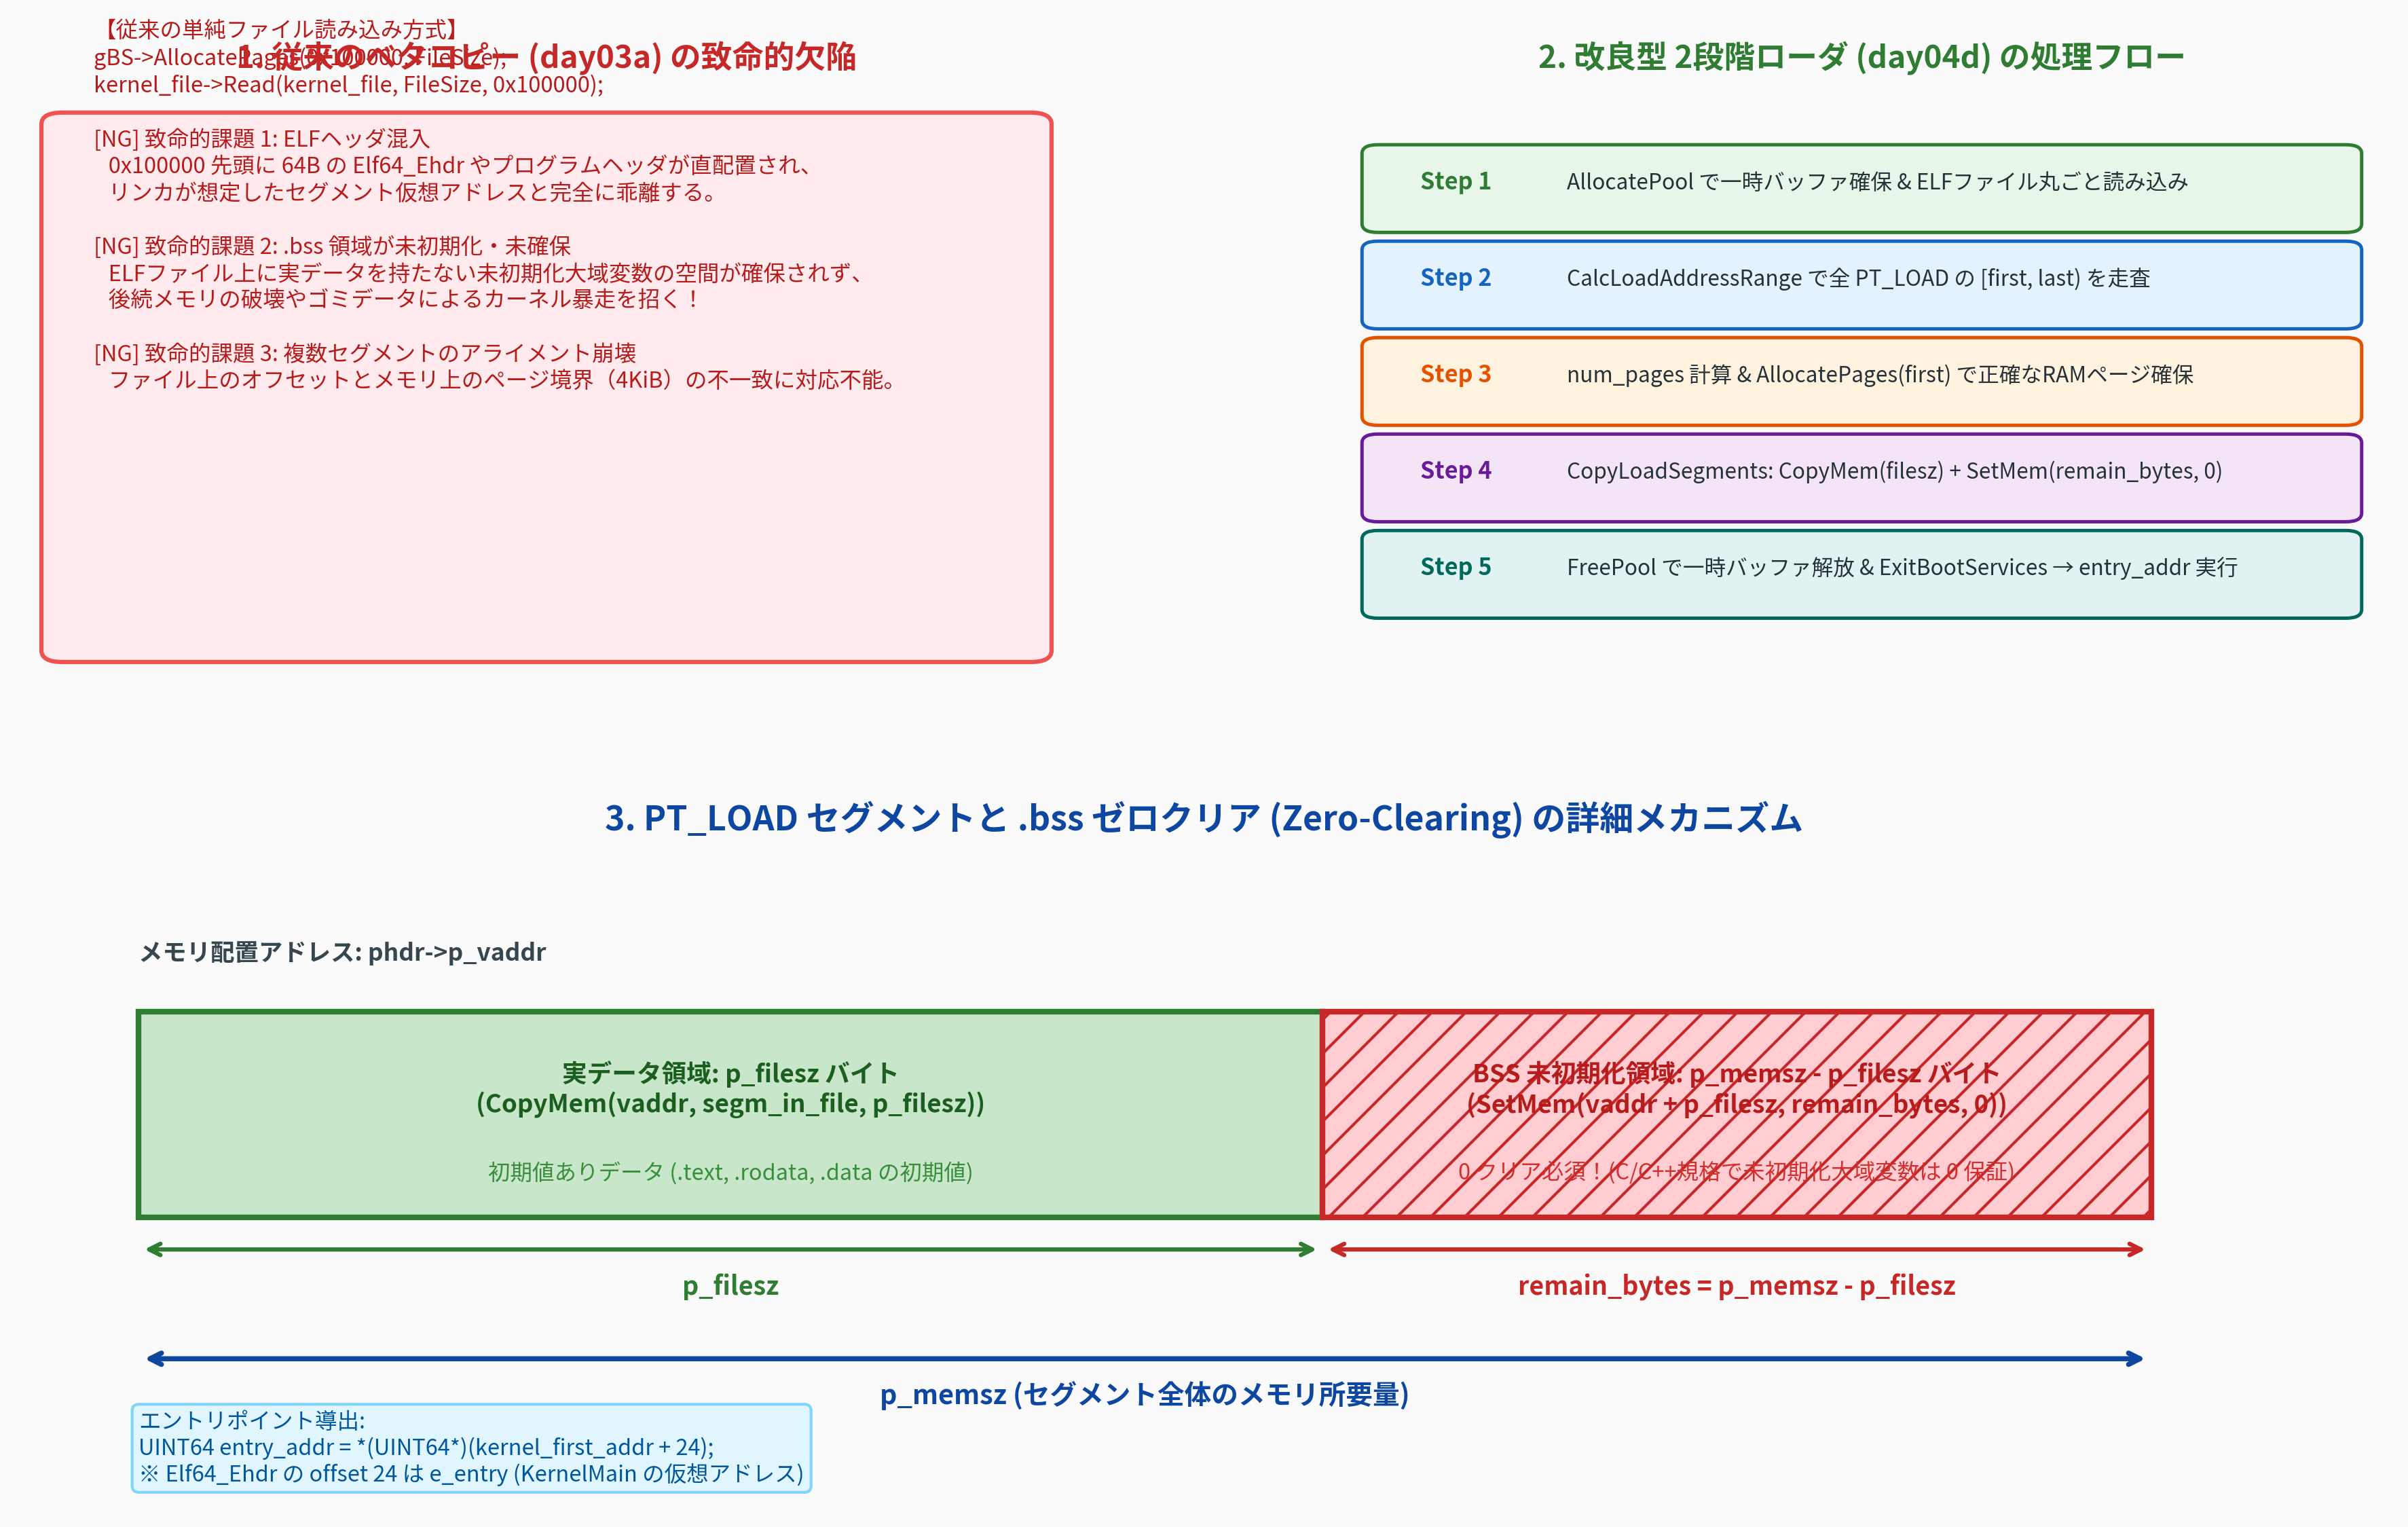

In [4]:
from IPython.display import Image, display
from common import (
    generate_fig4_09_elf_segment_structure,
    generate_fig4_10_pt_load_and_bss_clearing,
)

fig1_path = generate_fig4_09_elf_segment_structure("4/result/fig4_09_elf_segment_structure.png")
fig2_path = generate_fig4_10_pt_load_and_bss_clearing("4/result/fig4_10_pt_load_and_bss_clearing.png")

print("生成された図版を表示します:")
display(Image(filename=fig1_path, width=900))
display(Image(filename=fig2_path, width=900))


## 5. C++20 スタンドアロン検証と低レイヤ動作実証

ホスト側のスタンドアロン C++20 検証ターゲット（`src/ch04/elf_loader_sim.cpp`）をビルド・実行し、MikanOS の `Main.c` と同一の構造体・アライメント・ポインタ演算が正常に成立することを実証します。

### 検証項目
1. **ELF-64 構造体サイズとオフセットのアサーション**:
   - `sizeof(Elf64_Ehdr) == 64`
   - `sizeof(Elf64_Phdr) == 56`
   - `offsetof(Elf64_Ehdr, e_entry) == 24`
2. **`CalcLoadAddressRange` とページ計算の整合性**:
   - `PT_DYNAMIC` や `PT_NOTE` 等の非ロード対象セグメントを正しくスキップすること。
   - アドレススパンから4KiBページ数を正しく導出すること。
3. **`CopyLoadSegments` のデータ複写と `.bss` ゼロ埋め**:
   - 実データ領域（`p_filesz`）の忠実なコピーと、残余領域（`p_memsz - p_filesz`）の厳格なゼロ埋め。
4. **二段階ローダのライフサイクルとエントリポイント特定**:
   - 一時バッファからのアドレス計算 $\to$ ページ確保 $\to$ コピー $\to$ 一時バッファ解放 $\to$ `entry_addr` ジャンプ。


In [5]:
import subprocess

# C++20 検証プログラムのビルドと実行
res = subprocess.run(
    ["./build/bin/ch04_elf_loader_sim"],
    capture_output=True,
    text=True,
    check=True
)

print(res.stdout)


 MikanOS Chapter 4.5: ELF Loader & .bss Zero-Clear Verification  
[Test 1] Verifying ELF-64 header structures and offsets... PASSED (Ehdr: 64B, Phdr: 56B, EntryOffset: 24)
[Test 2] Verifying CalcLoadAddressRange & page calculation... PASSED (first: 0x100000, last: 0x102200, pages: 3)
[Test 3] Verifying CopyLoadSegments and .bss zero-clearing... PASSED (Code: CC, Data: 55, BSS: strictly zeroed)
[Test 4] Verifying two-stage loading flow & entry point resolution... PASSED (Entry point: 0x100080 verified)
[Test 5] Verifying loader edge cases (no PT_LOAD, empty)... PASSED (Non-LOAD handled safely)
 All Section 4.5 C++20 Verification Tests Passed Successfully!   



## 6. 総括と第4章の完成、そして第5章への展望

本節（4.5節）をもって、**第4章「ピクセル描画とmake入門」の全5節（4.1〜4.5）がすべて完成** しました！

### 第4章で到達したOSアーキテクチャの到達点

```text
第4章の技術的進化ロードマップ:
4.1 make入門         : Makefile による自動依存関係DAG解決と高速差分ビルドの確立
4.2 ピクセル描画・ABI: VRAM 2次元座標写像と System V AMD64 ABI レジスタ渡し規約の解明
4.3 C++ OOP 設計     : PixelWriter 多態性とヒープ不要の配置 new (Placement new)
4.4 vtable の深層    : 仮想関数テーブル、_vptr、Itanium C++ ABI、__cxa_pure_virtual ハルト保護
4.5 改良型ローダ     : ELF64 仕様準拠の PT_LOAD セグメント配置と .bss ゼロクリア
```

### 次なる挑戦: 第5章「文字表示とコンソールクラス」
カーネルを自由なセグメント構成で安全に起動できるようになった今、次なる課題は **「文字を描画し、画面にログを出力する」** ことです。
- **5.1節**: 8×16 ドットのフォントデータをビット単位で展開して文字を描く
- **5.2節**: ヘッダとソースファイルを分割してコンパイルする設計
- **5.3節**: `hankaku.txt` をオブジェクトファイル化してカーネルに組み込む
- **5.4節**: `sprintf` を使って数値を16進数や10進数で画面に表示する
- **5.5〜5.6節**: ターミナルのように画面スクロールする `Console` クラスと、OS開発の最重要デバッグ武器 `printk()` の実装！

第5章へ進む前に、第4章の演習問題（`4_Exercises.ipynb`）で本章の理解度を総点検しましょう！
